# 4.1.0-Tumor fraction per patient

**Inés Sentís**

Re-normalize tumor fraction only

Date of execution

In [1]:
Sys.Date()

[1] "2026-02-07"

## Libraries

In [2]:
suppressMessages(suppressWarnings({
library(Seurat)
library(Signac)
library(tidyverse)
library(scater) 
library(scran)
library(here)
library(glue)
}))

## Parameters

In [3]:
#here::dr_here(show_reason = TRUE)
source(here("utils/bin.R"))
source(here("utils/paths.R"))
source(here("AVGUSTINOVA_02_to_30/utils/style.R"))
source(here("AVGUSTINOVA_02_to_30/utils/variables.R"))

set.seed(0)

## Load Data

In [4]:
combined_obj <- readRDS(here(glue("{int}/{robj_dir}/4.0.5-integrated_filt.rds")))
DefaultAssay(combined_obj) <- "RNA"
combined_obj <- SetIdent(combined_obj, value=combined_obj@meta.data$cell_groups)

custom_order <- c('p2','p8','p14','p17','p13','p9','p7','p6','p15','p10','p16','p3','p5','p1','p4','p19')
combined_obj$patient <- factor(combined_obj$patient, level=custom_order)

In [5]:
# subset to tumor only
cs <- levels(combined_obj)[grep("Tumor", levels(combined_obj))]
combined_obj <- subset(combined_obj, idents=cs)

combined_obj <- DietSeurat(combined_obj,
                           counts = TRUE,
                           data = TRUE,
                           assays = c("ATAC_unified", "RNA"),
                           dimreducs = NULL,
                           graphs = NULL)

## Remove features with low counts

In [6]:
combined_obj

An object of class Seurat 
222285 features across 84275 samples within 2 assays 
Active assay: RNA (33555 features, 5605 variable features)
 1 other assay present: ATAC_unified

In [7]:
mt_genes <- grep("^MT-", rownames(combined_obj[["RNA"]]), value = TRUE)

In [8]:
keep_genes <- data.frame(rowSums(as.matrix(combined_obj[['RNA']]@counts)) >= 1)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
combined_obj[['RNA']]@counts <- combined_obj[['RNA']]@counts[rownames(keep_genes), ]
combined_obj[['RNA']]@data <- combined_obj[['RNA']]@data[rownames(keep_genes), ]

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 21.1 GiB”


In [9]:
combined_obj

An object of class Seurat 
222257 features across 84275 samples within 2 assays 
Active assay: RNA (33527 features, 5605 variable features)
 1 other assay present: ATAC_unified

### High variable features

Remove from HVG those genes with unusual high number of counts detected in _4.0.2-Explore_gene_counts_. For example MACROD2 appears in loadings of component 2 and its high number of counts might be driving the PCA. Also remove dimorfic genes according to [this paper](https://www.nature.com/articles/ncomms10717/figures/1).

In [10]:
list_objects <- SplitObject(combined_obj, split.by = "subproj")

In [11]:
genes_dmf <- c("XACT", "HTR2C","XIST", "DDX3Y","USP9Y","NLGN4Y", "KDM5D", "EIF1AY", "UBA1")
genes_out <- c(genes_dmf, top_c,mt_genes) 

In [12]:
find_hvgs <-  function(obj) {
    
    batch <- unique(obj$subproj)
    
    # remove genes from matrix before modulating variance and mean
    DefaultAssay(obj) <- "RNA"
    df_meta <- obj@meta.data
    counts <- obj[['RNA']]@counts
    counts <- counts[-(which(rownames(counts) %in% genes_out)),]
    obj2 <- CreateSeuratObject(counts = counts, meta.data = df_meta)
    
    # normalize again
    obj2 <- obj2 %>% 
            NormalizeData(
                normalization.method = "LogNormalize",
                scale.factor = 1e4) 
    
    # compute the variance and mean of the log-expression values 
    sce <- as.SingleCellExperiment(obj2)
    gene_var <- modelGeneVar(sce)
    
    tops <- gene_var %>% 
        as.data.frame() %>% 
        arrange(desc(total)) %>% 
        head(n=20)

    plt <- gene_var %>% 
      as.data.frame() %>% 
      ggplot(aes(mean, total)) +
      geom_point() +
      geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
      labs(x = "Mean of log-expression", y = "Variance of log-expression")+
      geom_text(data=tops, aes(mean,total,label=rownames(tops))) + 
      ggtitle(batch) + 
      theme(plot.title = element_text(hjust = 0.5, size = 12, face = "bold"))

    hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)
    return(list(plot = plt, hvgs_pat = hvgs))
}

In [13]:
modelling <- lapply(list_objects, find_hvgs)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


In [14]:
list_plots <- lapply(modelling, function(el) {
    el$plot
})

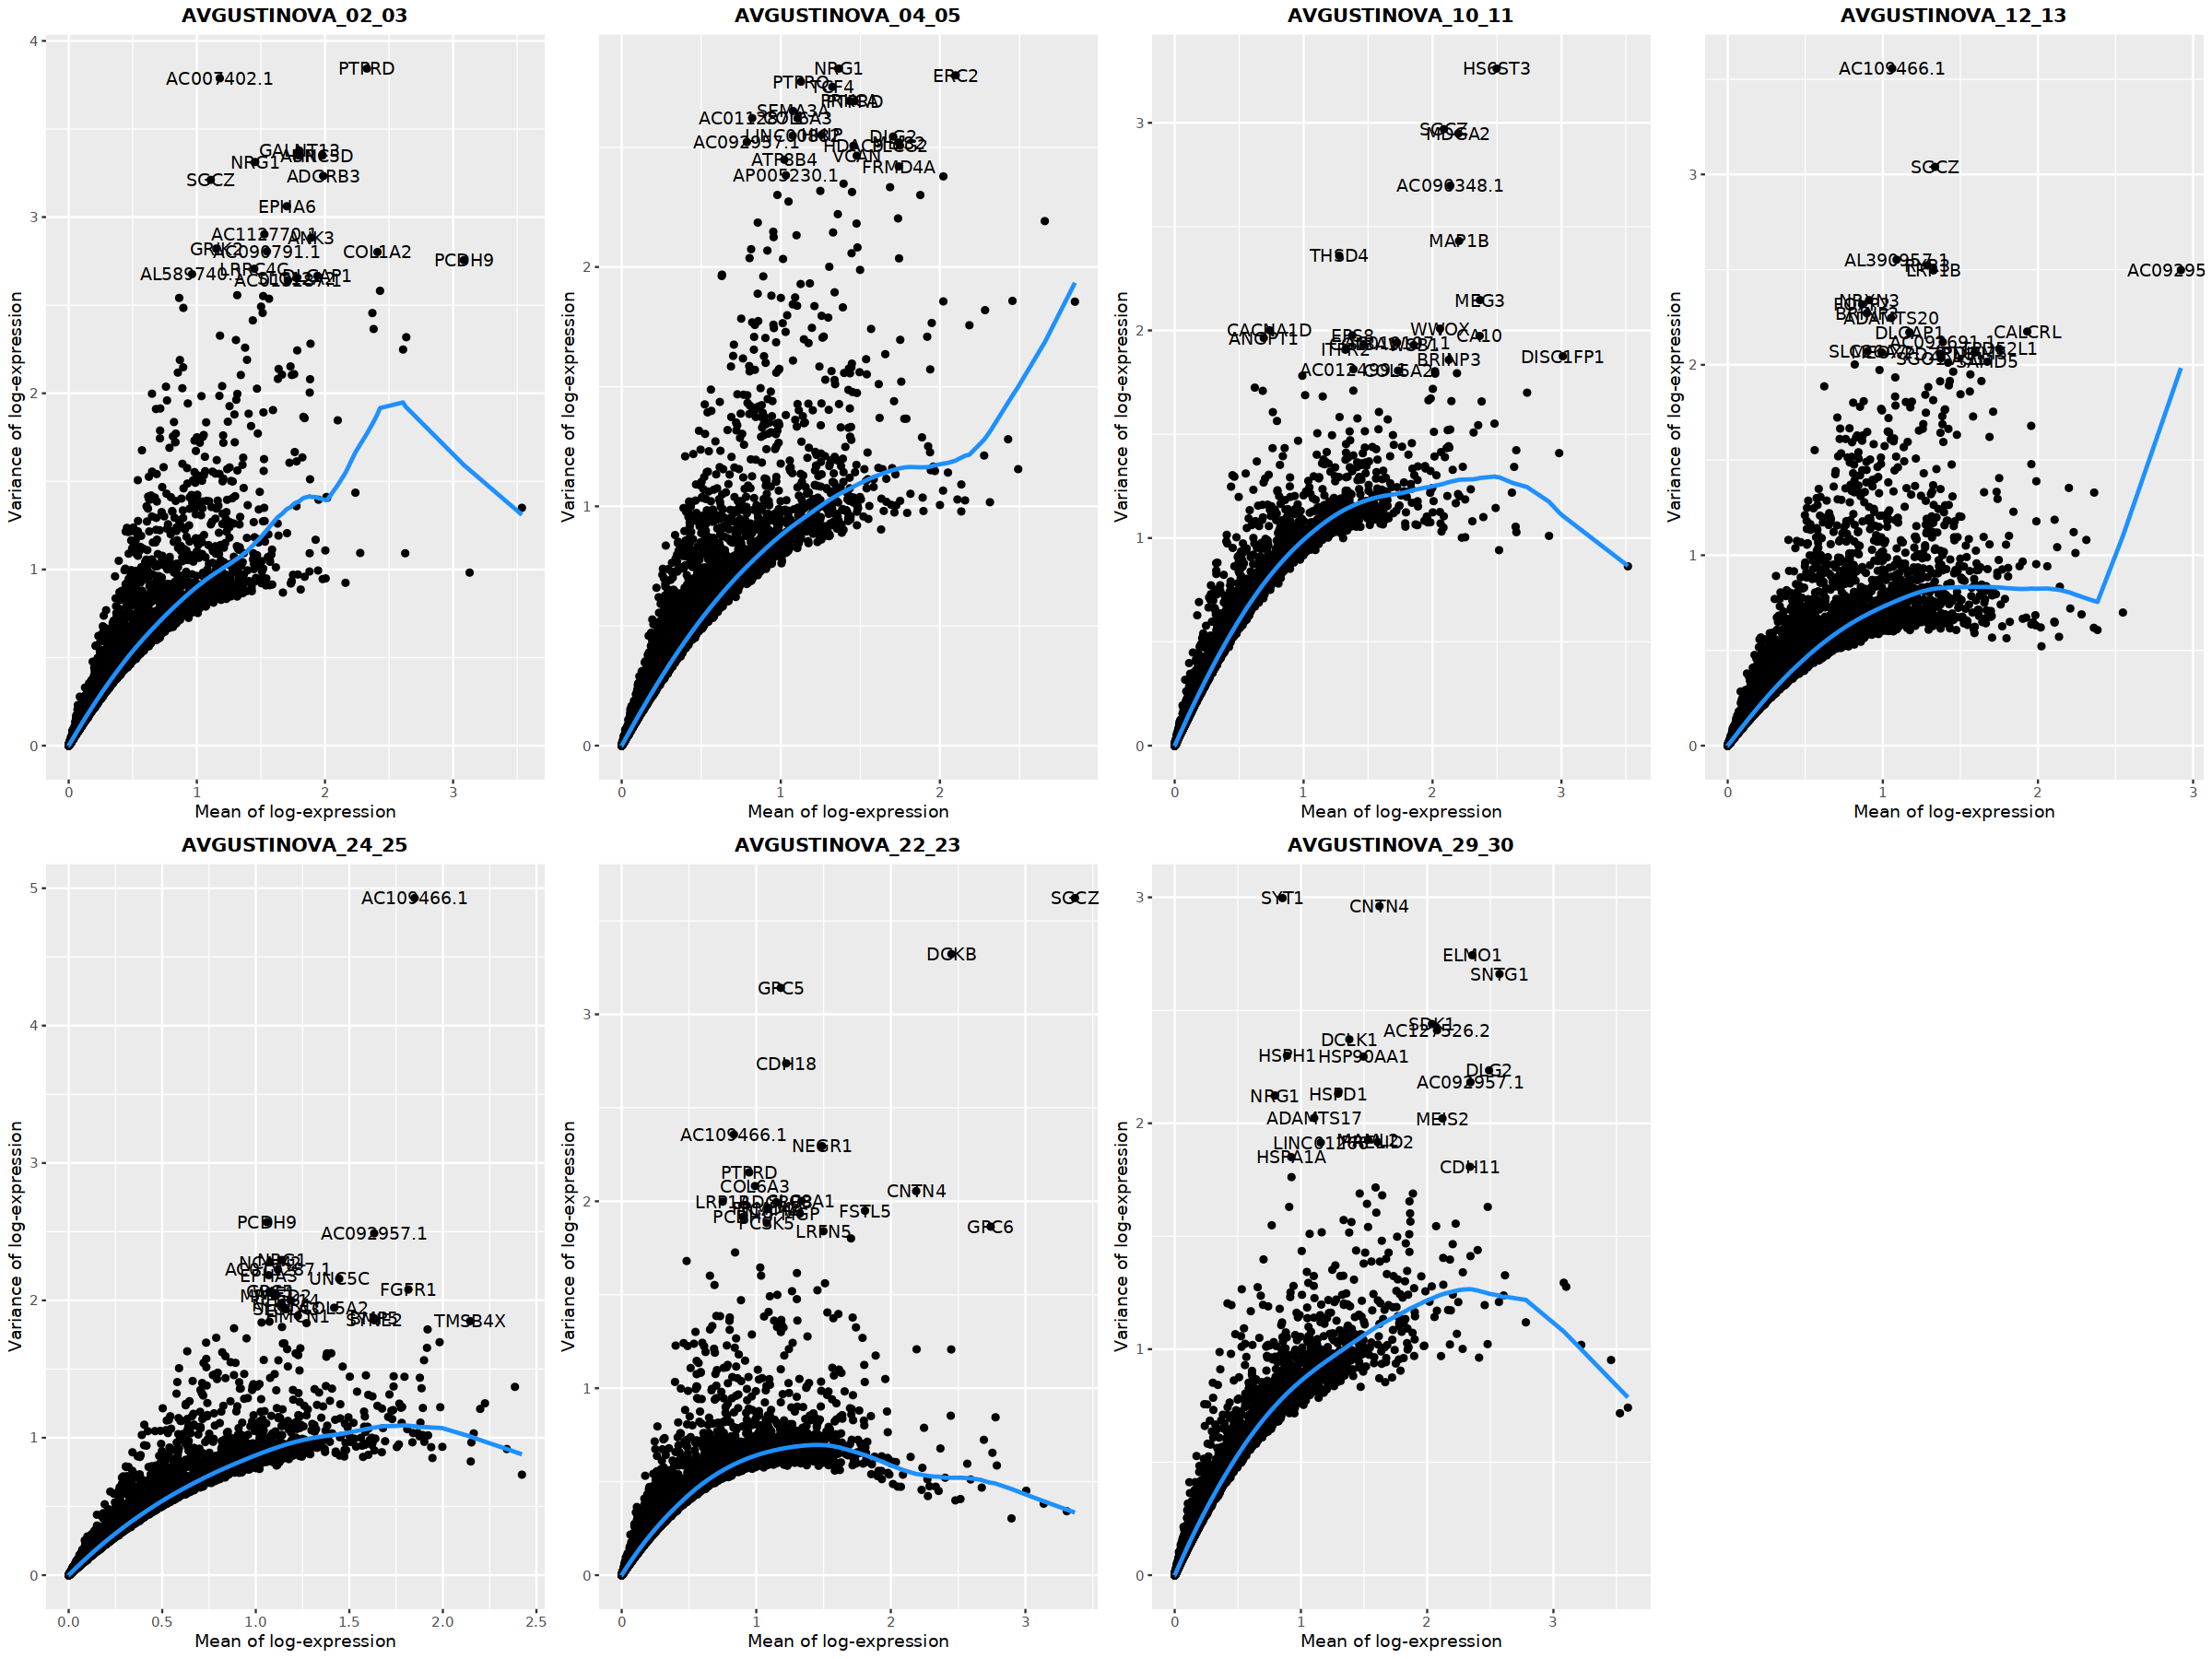

In [15]:
options(repr.plot.width = 20, repr.plot.height = 15)
cowplot::plot_grid(plotlist = list_plots,
                   align = "hv",
                   axis = "trbl",
                   ncol=4)

In [16]:
list_hvg <- lapply(modelling, function(el) {
    hvg <- el$hvgs_pat
    #hvg <- hvg[!hvg %in% genes_hc]
    print(length(hvg))
    hvg
})

[1] 650
[1] 2997
[1] 4365
[1] 724
[1] 2706
[1] 2577
[1] 2409


In [17]:
hvg_common <- find_perc(list_hvg, perc = 2/7)
length(hvg_common)

[1] 3550

In [18]:
#hvg_common <- Reduce(union, list_hvg)
#length(hvg_common)

In [19]:
list_hvp <- lapply(list_objects, function(obj) {
  DefaultAssay(obj) <- "ATAC_unified"
  hvp <-VariableFeatures(FindTopFeatures(obj[["ATAC_unified"]], min.cutoff = 20))
  return(hvp)
})

In [20]:
hvp_common <- Reduce(intersect, list_hvp)
length(hvp_common)

[1] 98638

In [21]:
combined_obj

An object of class Seurat 
222257 features across 84275 samples within 2 assays 
Active assay: RNA (33527 features, 5605 variable features)
 1 other assay present: ATAC_unified

In [22]:
remove(list_objects)

### Normalization and linear dimensional reduction

In [23]:
DefaultAssay(combined_obj) <- "ATAC_unified"
VariableFeatures(combined_obj) <- hvp_common
combined_obj <- RunTFIDF(combined_obj)
combined_obj <- RunSVD(combined_obj,features=hvp_common, reduction.name = "lsi.common")

Performing TF-IDF normalization

Running SVD

Scaling cell embeddings



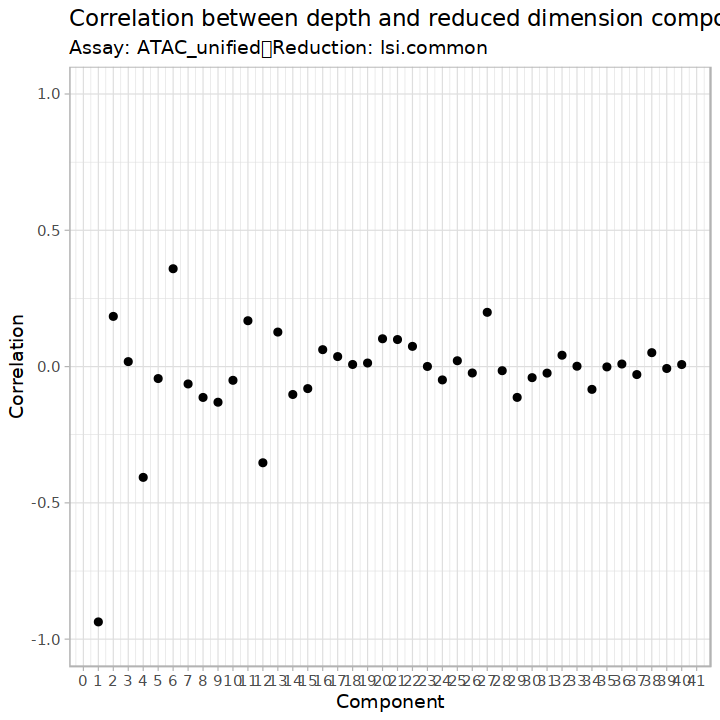

In [24]:
options(repr.plot.width = 6, repr.plot.height = 6)
DepthCor(combined_obj, reduction = "lsi.common", n=40)

In [25]:
atac_comp = 2:20

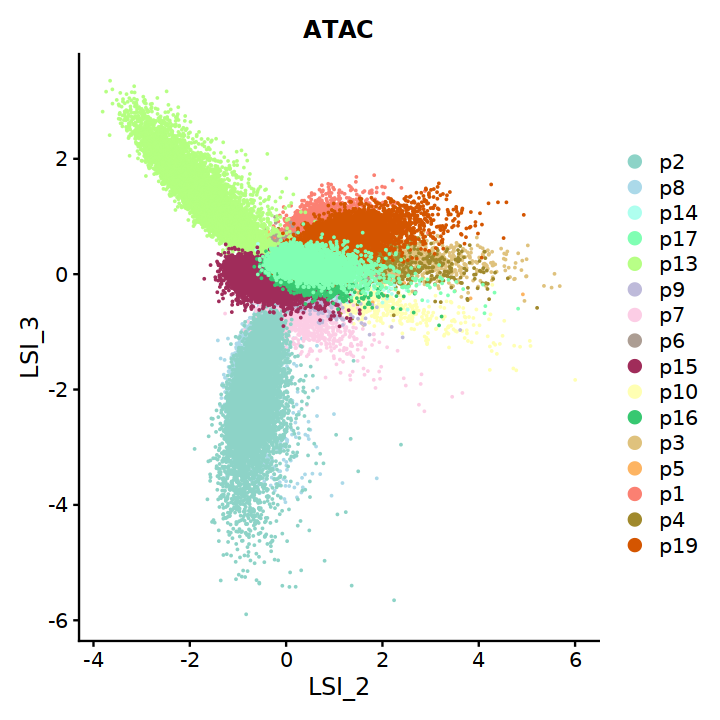

In [26]:
options(repr.plot.width = 6, repr.plot.height = 6)
DimPlot(combined_obj, reduction = "lsi.common", group.by = "patient", dims=c(2,3), cols=colors_patients,raster=FALSE) + 
  labs(title="ATAC")+
  theme(plot.title = element_text(hjust = 0.5, size = 14, face = "bold"))

In [27]:
DefaultAssay(combined_obj) <- "RNA"
 
VariableFeatures(combined_obj) <- hvg_common
combined_obj <- combined_obj %>% 
  NormalizeData(normalization.method = "LogNormalize",
                scale.factor = 1e4) %>%
  ScaleData(features=hvg_common) %>% 
  RunPCA(features=hvg_common) 

Centering and scaling data matrix

PC_ 1 
Positive:  TMSB4X, MEOX2, DCN, BMP5, COL5A2, COL3A1, ARHGAP28, TMSB10, HSP90AA1, S100A11 
	   PDGFC, AC011246.1, WIF1, AL390957.1, HGF, LURAP1L, ABCA8, S100A10, PPFIBP1, S100A6 
	   DNM3, ADAMTS6, SVIL, OLFM3, MPPED2, C5orf17, ATP2B1, DGKH, EPHA3, LINC01915 
Negative:  CLIC6, EPB41L4A, SAMD5, AL033504.1, ENPP2, MARK1, PDLIM5, TPD52L1, OCA2, SLCO3A1 
	   LDLRAD4, CDH2, EFEMP1, LINC00472, PDZRN3, ASXL3, TYR, PTPRM, LMX1A, TMEM108 
	   RYR3, RAI14, AGBL4, DTNA, MYO10, LEF1, ITGB8, DISP1, KLF12, PARD3B 
PC_ 2 
Positive:  MPPED2, WLS, CDK14, C5orf17, WIF1, PLAGL1, ARHGAP42, AC011586.2, COL19A1, EPHA3 
	   BACH2, MITF, FGFR1, AC244502.1, ZNF521, LURAP1L, SHROOM3, FARP1, NPNT, SGO1-AS1 
	   HLA-DPA1, SEMA6D, SAMMSON, BAMBI, CA2, CUX2, STARD13, LINC01915, PROM1, AC092957.1 
Negative:  AC090791.1, EDIL3, LINC01924, AHR, LRIG3, CHODL, NELL1, CARTPT, KCTD8, GALNT13 
	   SPINK5, EPHA6, AC112770.1, LINC02742, FRAS1, GNA14, KDR, VCAN, AGR2, AL359208.1 
	   A

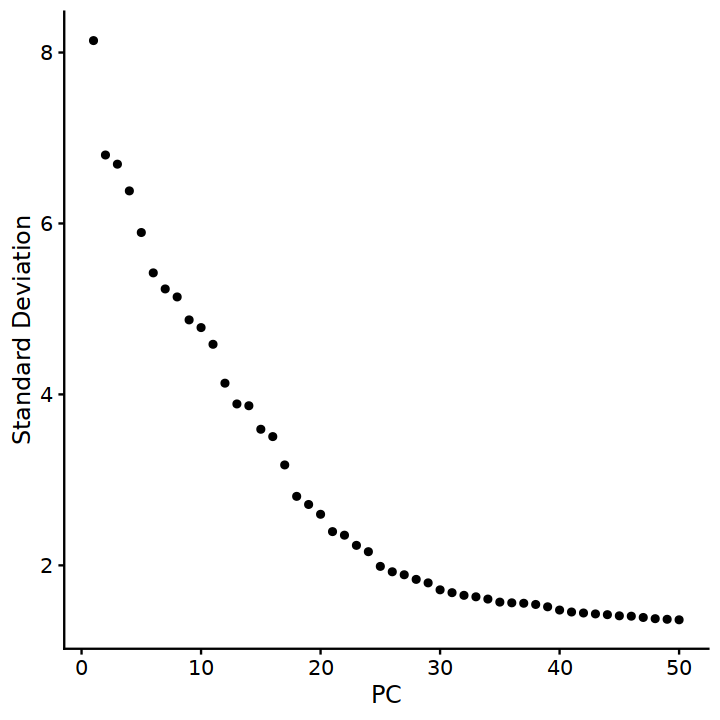

In [28]:
ElbowPlot(combined_obj, ndims=50)

In [29]:
rna_comp = 1:35

In [30]:
# Calculate the variance explained 
stdev <- Stdev(combined_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

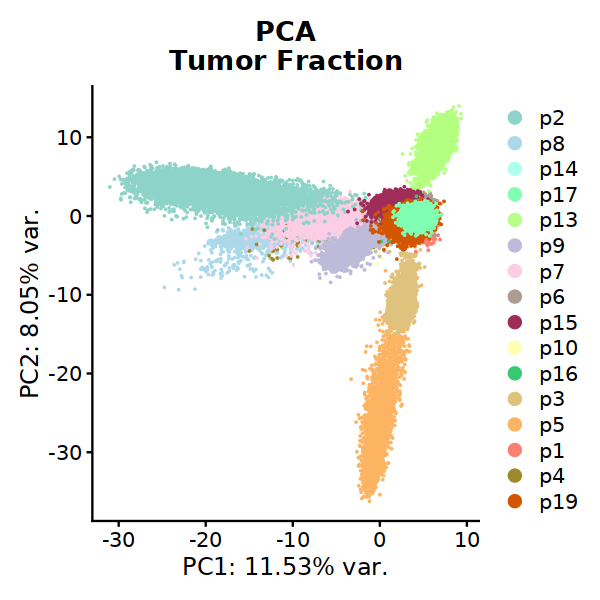

In [31]:
options(repr.plot.width = 5, repr.plot.height = 5)
pca_plt <- DimPlot(combined_obj, reduction = "pca", group.by = "patient", dims=c(1,2), cols=colors_patients) + 
  labs(title="PCA\nTumor Fraction") +
   xlab(pc1_label) +
   ylab(pc2_label) +
  theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
pca_plt

In [32]:
pc3_label <- paste0("PC3: ", round(var_explained[3], 2), "% var.")

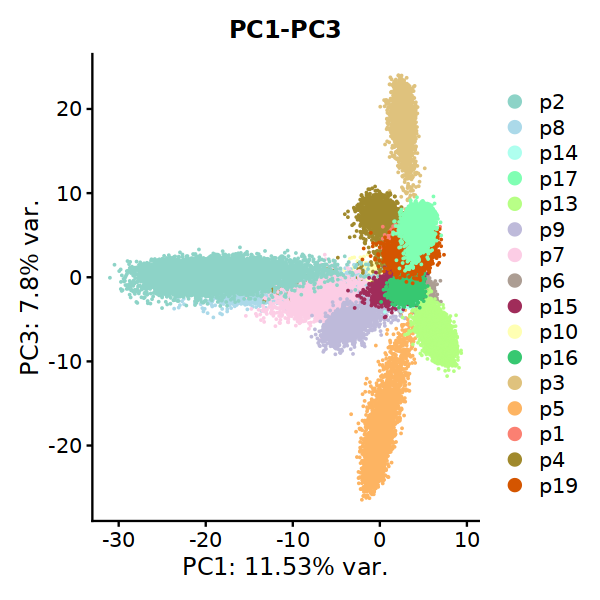

In [33]:
options(repr.plot.width = 5, repr.plot.height = 5)
DimPlot(combined_obj, reduction = "pca", group.by = "patient", dims=c(1,3),
        cols=colors_patients,raster=FALSE) + 
  labs(title="PC1-PC3") +
  xlab(pc1_label) +
  ylab(pc3_label) +
  theme(plot.title = element_text(hjust = 0.5, size = 14, face = "bold"))

### Harmony

In [34]:
combined_obj@reductions$pca_filt <- combined_obj@reductions$pca

combined_obj@reductions$pca_filt@cell.embeddings <- combined_obj@reductions$pca_filt@cell.embeddings[, rna_comp]

combined_obj@reductions$pca_filt@feature.loadings <- combined_obj@reductions$pca_filt@feature.loadings[, rna_comp]

In [35]:
library(harmony)
combined_obj <- RunHarmony(
  object = combined_obj,
  reduction = "pca_filt",
  group.by.vars = c("patient"),
  assay.use = "RNA",
  project.dim = T,
  reduction.save = "harmony_pca"
)

Loading required package: Rcpp

Warning message:
“package ‘Rcpp’ was built under R version 4.1.3”
Transposing data matrix

Harmony 1/10

Harmony 2/10

Harmony converged after 2 iterations

Warning message:
“Invalid name supplied, making object name syntactically valid. New object name is Seurat..ProjectDim.RNA.harmony_pca; see ?make.names for more details on syntax validity”


In [36]:
# Calculate the variance explained 
stdev <- Stdev(combined_obj, reduction = "harmony_pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

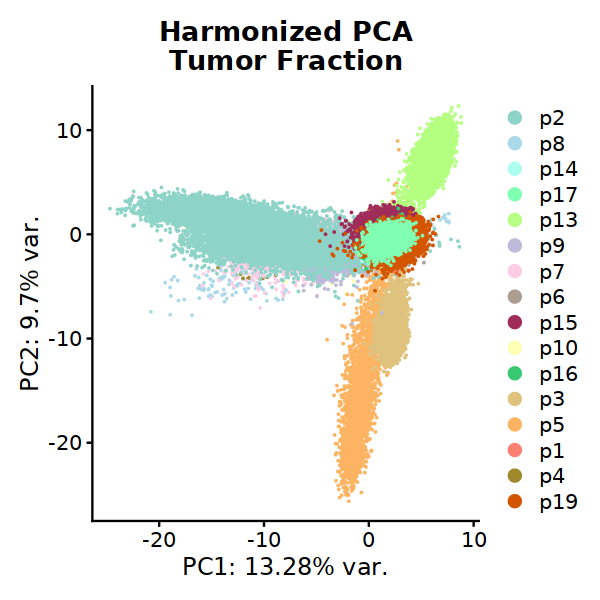

In [37]:
options(repr.plot.width = 5, repr.plot.height = 5)
pca_plt <- DimPlot(combined_obj, reduction = "harmony_pca", group.by = "patient", dims=c(1,2), cols=colors_patients) + 
  labs(title="Harmonized PCA\nTumor Fraction") +
   xlab(pc1_label) +
   ylab(pc2_label) +
  theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
pca_plt

In [38]:
ggsave(
  filename = here(glue("{int}/{plt_dir}/4.1.0-pca_rna.svg")),
  plot = pca_plt,
  width = 5,
  height = 5,
  dpi = 500,
  device = "svg"
)

In [39]:
all_loadings <- Loadings(combined_obj, reduction = "pca")
#colnames(all_loadings) <- gsub("harmonypca_", "PC_",colnames(all_loadings))

get_pc_genes <- function(loadings_matrix, pc_num, n_top = 25) {
  
  pc_col <- paste0("PC_", pc_num)
  
  # Extract PC
  pc_data <- data.frame(
    Gene = rownames(loadings_matrix),
    Loading = loadings_matrix[, pc_col]
  )
  
  # Get Top Positive
  pos_data <- pc_data %>%
    arrange(desc(Loading)) %>%
    head(n_top) %>%
    mutate(Direction = "Positive", PC = pc_col)
  
  # Get Top Negative
  neg_data <- pc_data %>%
    arrange(Loading) %>% 
    head(n_top) %>%
    mutate(Direction = "Negative", PC = pc_col)
  
  return(rbind(pos_data, neg_data))
}

pc1_data <- get_pc_genes(all_loadings, 1, n_top = 25)
pc2_data <- get_pc_genes(all_loadings, 2, n_top = 25)
plot_data <- rbind(pc1_data, pc2_data)


plot_data <- plot_data %>%
  mutate(gene_within_facet = paste(Gene, PC, Direction, sep = "__")) %>%
  mutate(gene_within_facet = reorder(gene_within_facet, abs(Loading)))


pcl <- ggplot(plot_data, aes(x = Loading, y = gene_within_facet)) +
  
  geom_point(size = 3, aes(color = Direction)) +
  geom_segment(aes(x = 0, xend = Loading, yend = gene_within_facet, color = Direction), size = 0.5) +
  facet_wrap(PC ~ Direction, scales = "free", ncol = 2) +
  scale_y_discrete(labels = function(x) sub("__.*", "", x)) +
  theme_bw(base_size = 14) +
  
  scale_color_manual(values = c("Positive" = "#E41A1C", "Negative" = "#377EB8")) +
  
  labs(
    title = "Top PCA Loadings",
    x = "PCA Loading Score",
    y = "Gene"
  ) +
  
  theme(
    panel.grid.major.y = element_line(color = "grey90", linetype = "dashed"),
    panel.grid.minor = element_blank(),
    legend.position = "none",
    axis.text.x = element_text(color="black"),
    axis.text.y = element_text(color="black"),  
    strip.background = element_rect(fill = "grey90"),
    strip.text = element_text(color = "black", face = "bold", size = 12)
  )

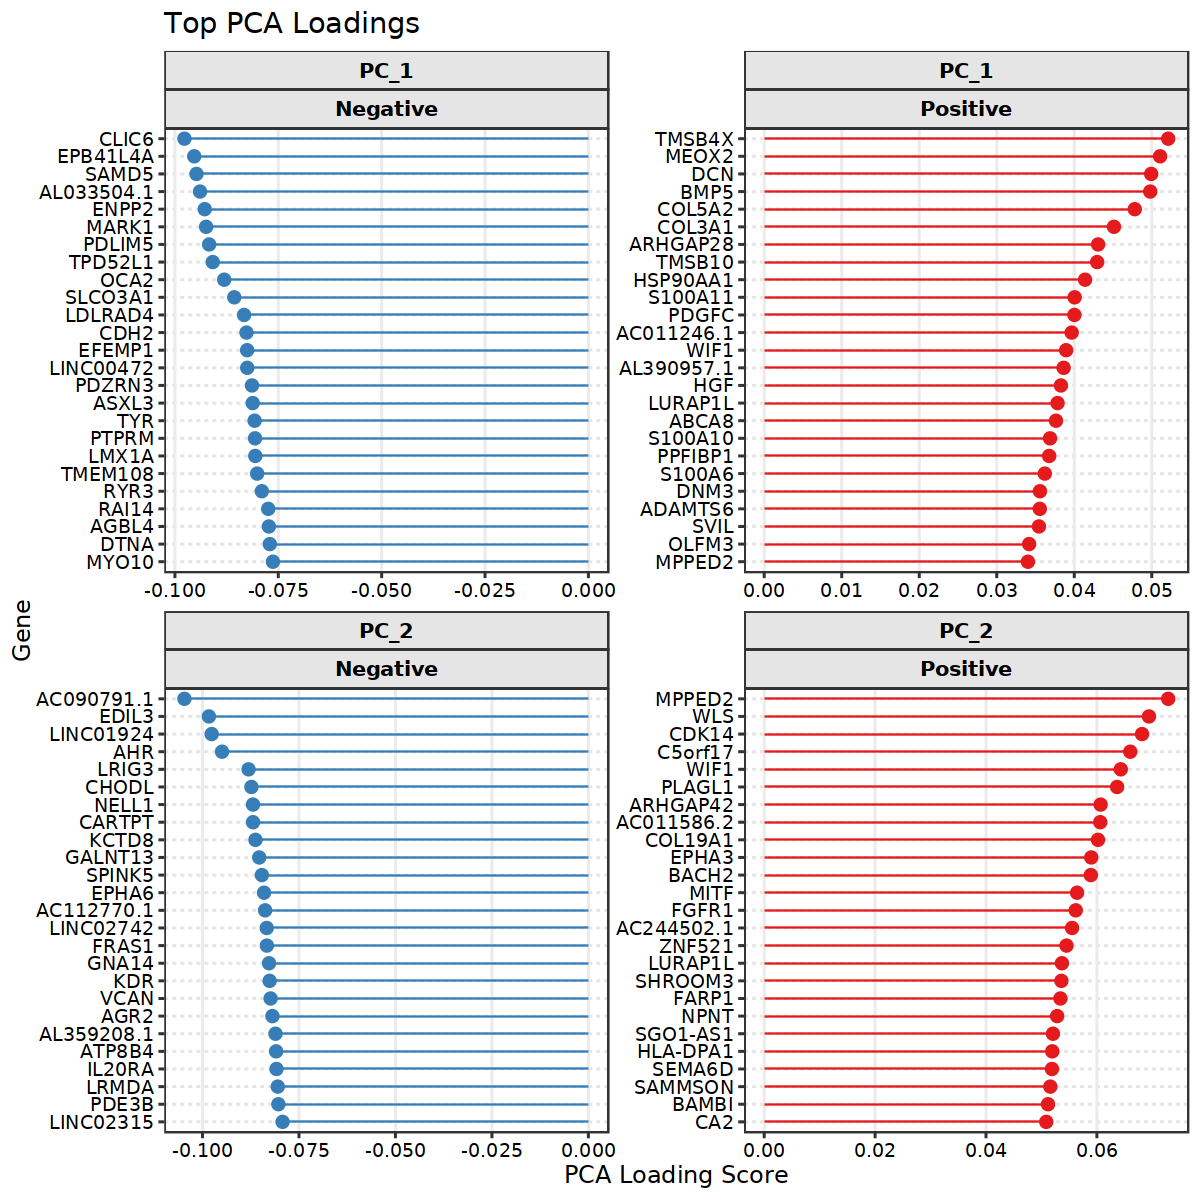

In [40]:
options(repr.plot.width = 10, repr.plot.height = 10)
pcl

In [41]:
ggsave(
  filename = here(glue("{int}/{plt_dir}/4.1.0-pca_loadings.svg")),
  plot = pcl,
  width = 10,
  height = 10,
  dpi = 500,
  device = "svg"
)

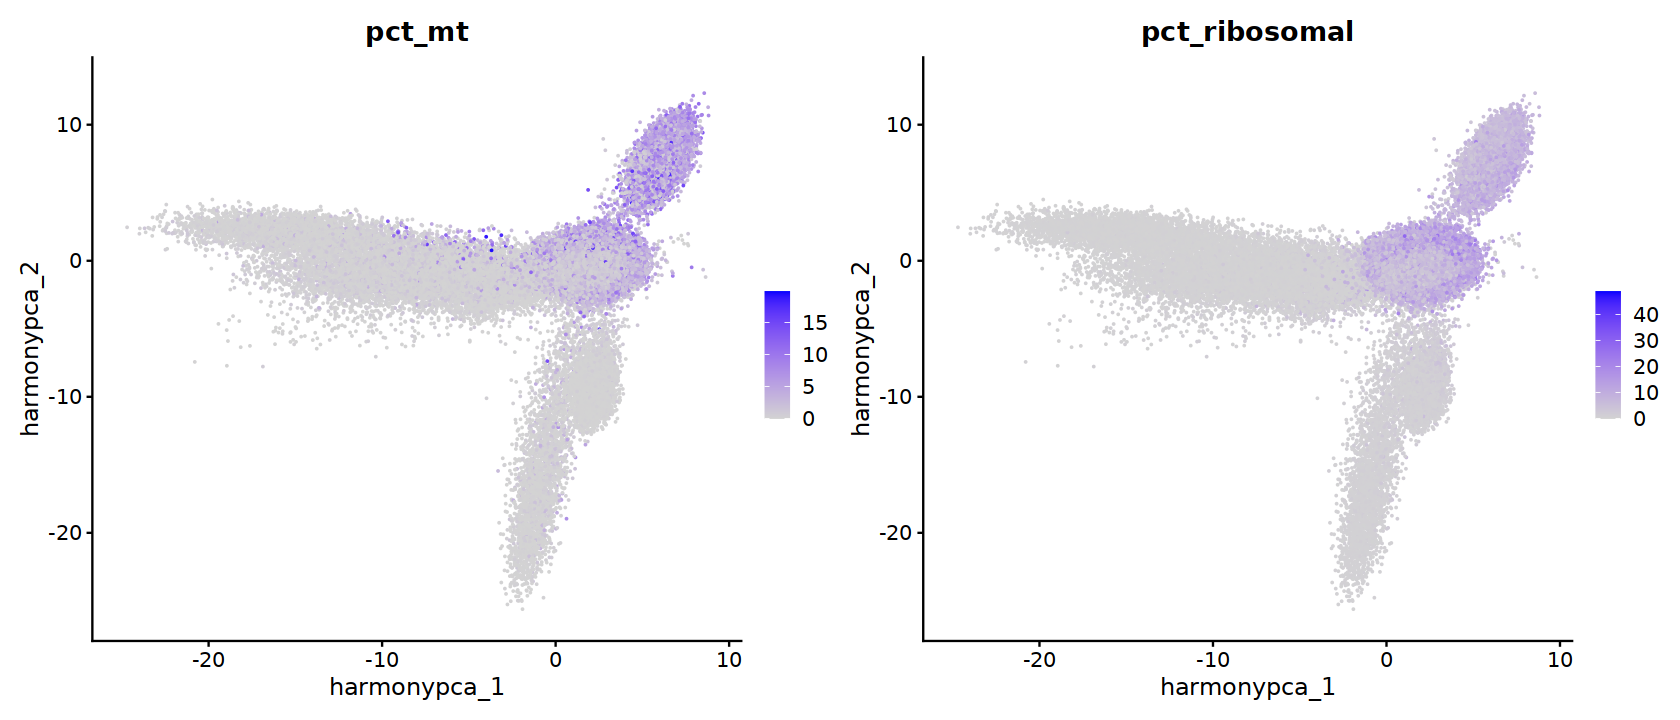

In [42]:
options(repr.plot.width = 14, repr.plot.height = 6)
FeaturePlot(combined_obj, reduction = "harmony_pca", features = c("pct_mt", "pct_ribosomal"))

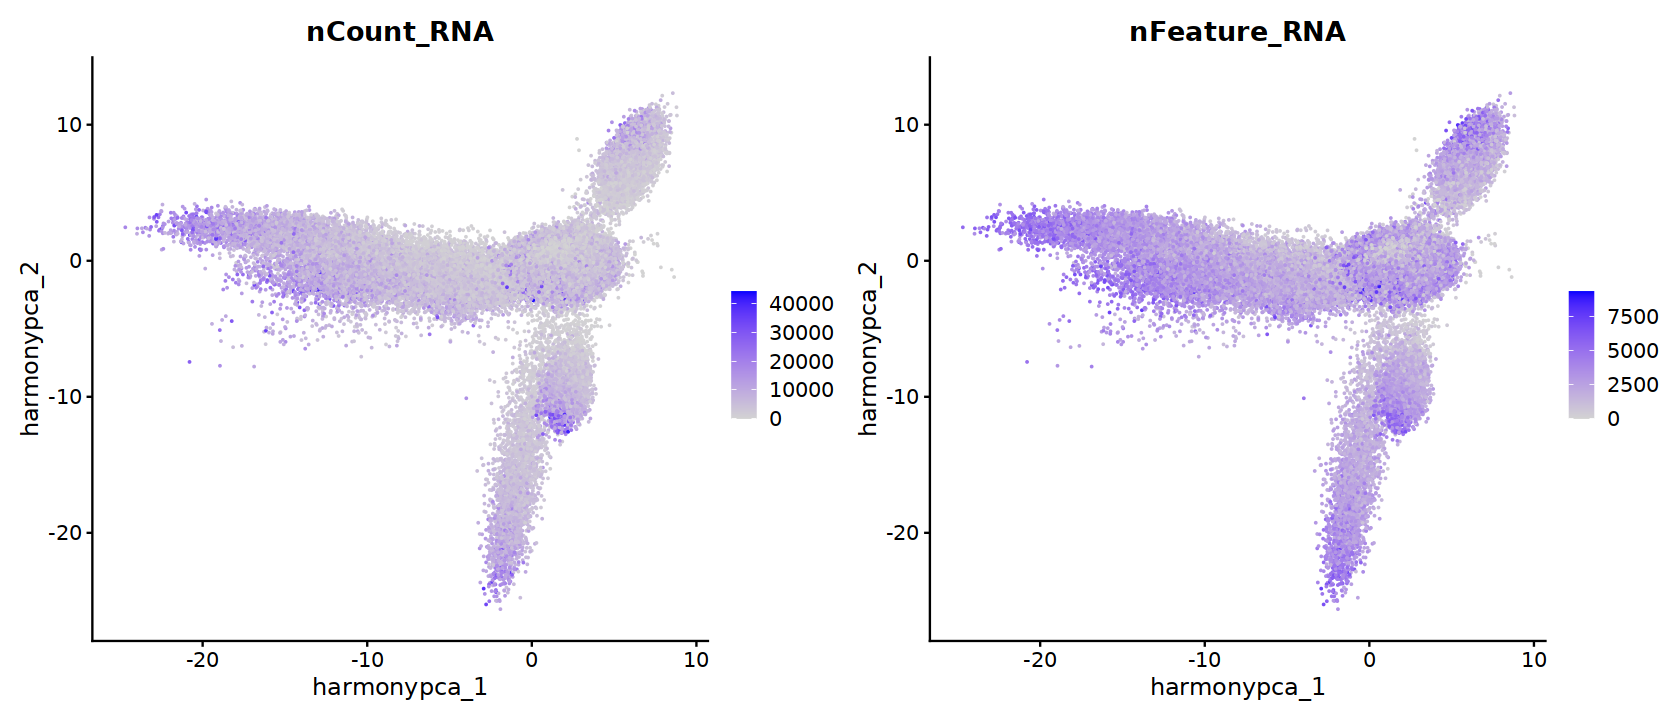

In [43]:
options(repr.plot.width = 14, repr.plot.height = 6)
FeaturePlot(combined_obj, reduction = "harmony_pca", features = c("nCount_RNA", "nFeature_RNA"))

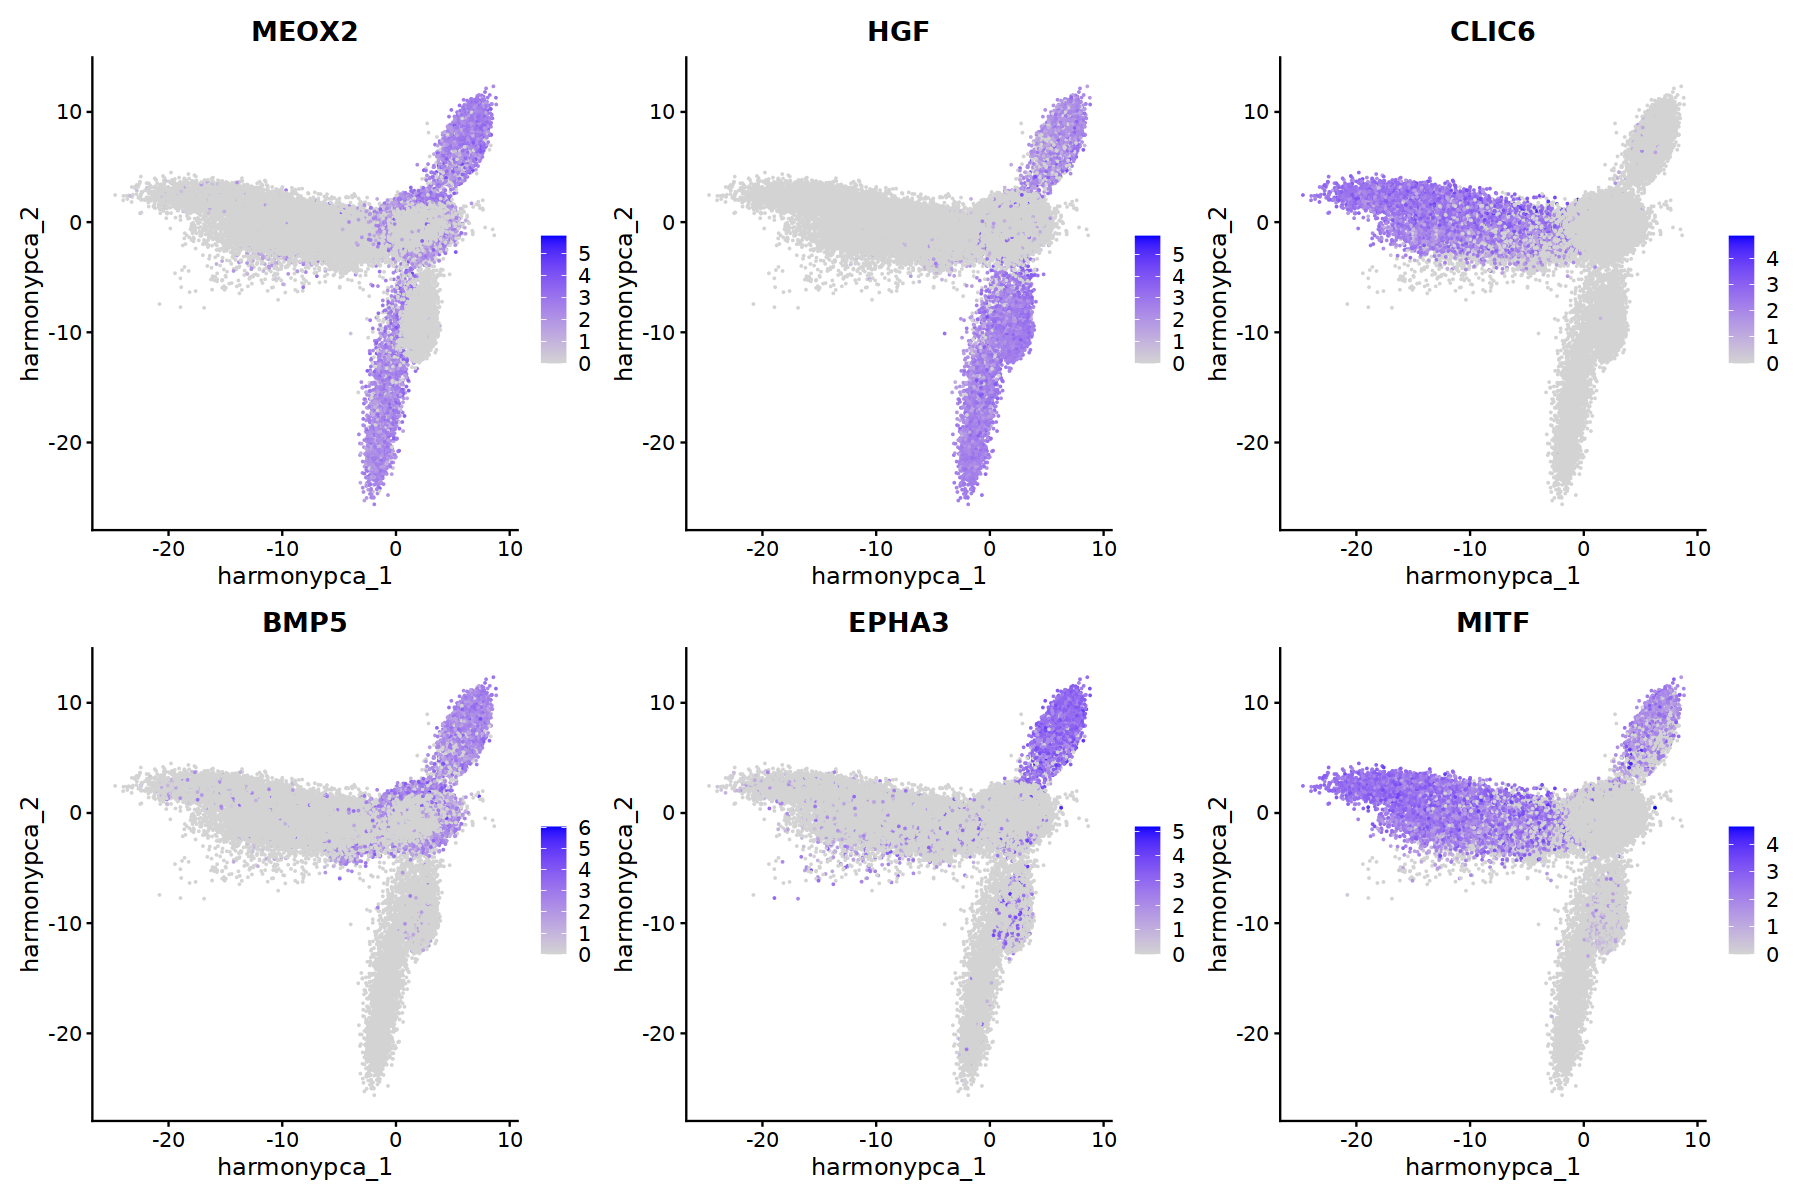

In [44]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(combined_obj, reduction = "harmony_pca", ncol=3, order=F,
            features = c("MEOX2", "HGF", "CLIC6","BMP5","EPHA3","MITF"))

## Save

In [45]:
saveRDS(combined_obj, here(glue("{int}/{robj_dir}/4.1.0-tumor_fraction.rds")))

In [46]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] harmony_1.0.3               Rcpp_1.0.10                
 [3] glue_1.6.2                  here_1.0.1                 
 [5] scran_1.22.1                scater_1.22.0              
 [7] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [9] SummarizedExperime